# **Actividad 2: Modelos de predicción y clasificación** 
En este notebook se construye el flujo de trabajo completo para la segunda parte del proyecto modelos de predicción y clasificación del dataset llamado "California housing" o en español "Viviendas de California".

In [1]:
# Importaciones 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import platform
import sklearn
from datetime import datetime
from pathlib import Path
from datasets import load_dataset
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

## **0. Construcción automática del DataFrame**

**Dataset:** California Housing, basado en el censo de California de 1990.  
**Identificador:** `BrianSuToronto/california_housing`  
**Enlace:** https://huggingface.co/datasets/BrianSuToronto/california_housing  
**Split utilizado:** `train`  
**Contenido:** Cada fila describe una zona (bloque del censo) con sus características demográficas, de vivienda y de ubicación.  
**Columnas relevantes (ya renombradas):** `Ingreso_mediano`, `Edad_vivienda`, `Promedio_habitaciones`, `Promedio_dormitorio_hogar`, `Poblacion`, `Promedio_ocupacion`, `Latitud`, `Longitud` y `Valor_mediano_vivienda`.    
**Problema de regresión:** Predecir `Valor_mediano_vivienda` (numérica continua).  
**Problema de clasificación:** Predecir `Categoria_valor` (Bajo, Medio, Alto), construida a partir de `Valor_mediano_vivienda`.

### Creación y carga del dataset

In [2]:
DATASET = "BrianSuToronto/california_housing"   
SPLIT = "train"

ds = load_dataset(DATASET)
print("Splits disponibles:", list(ds.keys()))
df = ds[SPLIT].to_pandas()

Splits disponibles: ['train']


### Renombrado de columnas

In [3]:
nombres_columnas = {
    "MedInc": "Ingreso_mediano",
    "HouseAge": "Edad_vivienda",
    "AveRooms": "Promedio_habitaciones",
    "AveBedrms": "Promedio_dormitorio_hogar",
    "Population": "Poblacion",
    "AveOccup": "Promedio_ocupacion",
    "Latitude": "Latitud",
    "Longitude": "Longitud",
    "MedHouseVal": "Valor_mediano_vivienda",
}

df_transformado = df.rename(columns=nombres_columnas)
print(df_transformado.shape)
display(df_transformado.head(3))

(20640, 9)


,Ingreso_mediano,Edad_vivienda,Promedio_habitaciones,Promedio_dormitorio_hogar,Poblacion,Promedio_ocupacion,Latitud,Longitud,Valor_mediano_vivienda
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521


### Mostramos contenido del DataFrame

In [4]:
# Mostramos el DataFrame
print("DataFrame de 'California_Housing'")
print("\n- Tamaño (filas, columnas):", df_transformado.shape)
print("- Columnas:", df_transformado.columns.tolist())
print("- Tipos de datos:")
print(df_transformado.dtypes)
print("\nContenido del DataFrame:")
display(df_transformado.head(3))

DataFrame de 'California_Housing'

- Tamaño (filas, columnas): (20640, 9)
- Columnas: ['Ingreso_mediano', 'Edad_vivienda', 'Promedio_habitaciones', 'Promedio_dormitorio_hogar', 'Poblacion', 'Promedio_ocupacion', 'Latitud', 'Longitud', 'Valor_mediano_vivienda']
- Tipos de datos:
Ingreso_mediano              float64
Edad_vivienda                float64
Promedio_habitaciones        float64
Promedio_dormitorio_hogar    float64
Poblacion                    float64
Promedio_ocupacion           float64
Latitud                      float64
Longitud                     float64
Valor_mediano_vivienda       float64
dtype: object

Contenido del DataFrame:


,Ingreso_mediano,Edad_vivienda,Promedio_habitaciones,Promedio_dormitorio_hogar,Poblacion,Promedio_ocupacion,Latitud,Longitud,Valor_mediano_vivienda
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521


### Definición de las variables objetivo (regresión y clasificación)

In [5]:
# Regla: tres categorías con la misma cantidad de zonas (terciles)
df_modelo = df_transformado.assign(
    Categoria_valor=pd.qcut(
        df_transformado["Valor_mediano_vivienda"],
        q=3,
        labels=["Bajo", "Medio", "Alto"],
    )
)

print(df_modelo["Categoria_valor"].value_counts())
print(df_modelo.groupby("Categoria_valor", observed=False)["Valor_mediano_vivienda"].agg(["min", "max"]))

Categoria_valor
Bajo     6884
Alto     6880
Medio    6876
Name: count, dtype: int64
                     min      max
Categoria_valor                  
Bajo             0.14999  1.41400
Medio            1.41500  2.30300
Alto             2.30400  5.00001


**Regla de clasificación:** Se creó una variable categórica a partir de la variable numérica `Valor_mediano_vivienda`, dividiéndola en terciles con `pd.qcut`, de modo que cada categoría (Bajo, Medio, Alto) tiene aproximadamente la misma cantidad de zonas. Se eligió esta regla porque deja clases balanceadas, lo que evita que el modelo aprenda a predecir siempre la clase mayoritaria. La variable `Valor_mediano_vivienda` no se incluye entre las predictoras de clasificación, porque revelaría directamente la respuesta.

## **1. Evidencia de preprocesamiento**

### Estado inicial

In [6]:
# ANTES este es el estado inicial 
print("Tamaño:", df_modelo.shape)
print("\nTipos:\n", df_modelo.dtypes)
print("\nNulos por columna:\n", df_modelo.isna().sum())
print("\nDuplicados:", df_modelo.duplicated().sum())

display(df_modelo.describe().T)

# Asimetría y valores atípicos (regla del IQR) de las predictoras
predictoras = [c for c in df_modelo.columns if c not in ["Valor_mediano_vivienda", "Categoria_valor"]]
asimetria_antes = df_modelo[predictoras].skew().round(2)
print("\nAsimetría antes:\n", asimetria_antes)

q1, q3 = df_modelo[predictoras].quantile(0.25), df_modelo[predictoras].quantile(0.75)
iqr = q3 - q1
atipicos = ((df_modelo[predictoras] < q1 - 1.5 * iqr) | (df_modelo[predictoras] > q3 + 1.5 * iqr)).sum()
print("\nValores atípicos por columna:\n", atipicos)

Tamaño: (20640, 10)

Tipos:
 Ingreso_mediano               float64
Edad_vivienda                 float64
Promedio_habitaciones         float64
Promedio_dormitorio_hogar     float64
Poblacion                     float64
Promedio_ocupacion            float64
Latitud                       float64
Longitud                      float64
Valor_mediano_vivienda        float64
Categoria_valor              category
dtype: object

Nulos por columna:
 Ingreso_mediano              0
Edad_vivienda                0
Promedio_habitaciones        0
Promedio_dormitorio_hogar    0
Poblacion                    0
Promedio_ocupacion           0
Latitud                      0
Longitud                     0
Valor_mediano_vivienda       0
Categoria_valor              0
dtype: int64

Duplicados: 0


,count,mean,std,min,25%,50%,75%,max
Ingreso_mediano,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
Edad_vivienda,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
Promedio_habitaciones,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
Promedio_dormitorio_hogar,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Poblacion,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
Promedio_ocupacion,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitud,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitud,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
Valor_mediano_vivienda,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010



Asimetría antes:
 Ingreso_mediano               1.65
Edad_vivienda                 0.06
Promedio_habitaciones        20.70
Promedio_dormitorio_hogar    31.32
Poblacion                     4.94
Promedio_ocupacion           97.64
Latitud                       0.47
Longitud                     -0.30
dtype: float64

Valores atípicos por columna:
 Ingreso_mediano               681
Edad_vivienda                   0
Promedio_habitaciones         511
Promedio_dormitorio_hogar    1424
Poblacion                    1196
Promedio_ocupacion            711
Latitud                         0
Longitud                        0
dtype: int64


El dataset contiene 9 variables numéricas de tipo float y solo una categorica que fue la agregada por nosotros anteriormente, no contiene datos  nulos, ni duplicados, las columnas que contienen más valores atípicos son Promedio_dormitorio_hogar y Poblacion , siguiendoles Promedio_ocupacion e Ingreso_mediano.

### Operaciones realizadas (No aprenden de los datos)

#### Duplicados

In [7]:
# Verificación de duplicados
# No hay duplicados solo se copia el dataframe
df_prep = df_modelo.copy()
print("Duplicados encontrados:", df_modelo.duplicated().sum())
print("Filas:", len(df_prep))

Duplicados encontrados: 0
Filas: 20640


#### Enriquecimiento de variables

In [8]:
# Enriquecimiento de variables 

# Evidencia que justifica la variable nueva (se calcula antes del logaritmo)
print("Correlación entre habitaciones y dormitorios:")
print(df_prep[["Promedio_habitaciones", "Promedio_dormitorio_hogar"]].corr().round(3))

# Creación de la variable: habitaciones por cada dormitorio
df_prep = df_prep.assign(
    Habitaciones_por_dormitorio=df_prep["Promedio_habitaciones"] / df_prep["Promedio_dormitorio_hogar"]
)

# Validación: no debe haber infinitos ni nulos
invalidos = df_prep["Habitaciones_por_dormitorio"].replace([np.inf, -np.inf], np.nan).isna().sum()
print("\nValores infinitos o nulos:", invalidos)

# Muestra y estadísticas de la variable nueva
display(df_prep[["Promedio_habitaciones", "Promedio_dormitorio_hogar", "Habitaciones_por_dormitorio"]].head())
display(df_prep["Habitaciones_por_dormitorio"].describe())

# Se agrega a las predictoras (solo si no está) y se recalcula la asimetría "antes"
if "Habitaciones_por_dormitorio" not in predictoras:
    predictoras.append("Habitaciones_por_dormitorio")

asimetria_antes = df_prep[predictoras].skew().round(2)
print("\nNúmero de predictoras:", len(predictoras))

Correlación entre habitaciones y dormitorios:
                           Promedio_habitaciones  Promedio_dormitorio_hogar
Promedio_habitaciones                      1.000                      0.848
Promedio_dormitorio_hogar                  0.848                      1.000

Valores infinitos o nulos: 0


,Promedio_habitaciones,Promedio_dormitorio_hogar,Habitaciones_por_dormitorio
0,6.984127,1.023810,6.821705
1,6.238137,0.971880,6.418626
2,8.288136,1.073446,7.721053
3,5.817352,1.073059,5.421277
4,6.281853,1.081081,5.810714


count    20640.000000
mean         4.984262
std          1.171836
min          1.000000
25%          4.169542
50%          4.921728
75%          5.700424
max         10.000000
Name: Habitaciones_por_dormitorio, dtype: float64


Número de predictoras: 9


Las columnas `Promedio_habitaciones` y `Promedio_dormitorio_hogar` tienen una correlación de **0.848** (calculada con `corr()`): están relacionadas, pero cada una aporta información propia. La variable `Habitaciones_por_dormitorio` resume cuántas habitaciones hay por cada dormitorio, una relación que un modelo lineal no puede formar por sí solo a partir de las dos columnas por separado.

#### Transformaciones logarítmicas

In [9]:
# Transformación logarítmica de variables muy sesgadas
df_prep = df_prep.assign(
    Promedio_ocupacion=np.log1p(df_prep["Promedio_ocupacion"]),
    Promedio_dormitorio_hogar=np.log1p(df_prep["Promedio_dormitorio_hogar"]),
    Promedio_habitaciones=np.log1p(df_prep["Promedio_habitaciones"]),
    Poblacion=np.log1p(df_prep["Poblacion"])
)

asimetria_despues = df_prep[predictoras].skew().round(2)
display(pd.DataFrame({"antes": asimetria_antes, "despues": asimetria_despues}))

,antes,despues
Ingreso_mediano,1.65,1.65
Edad_vivienda,0.06,0.06
Promedio_habitaciones,20.70,1.39
Promedio_dormitorio_hogar,31.32,8.99
Poblacion,4.94,-1.04
Promedio_ocupacion,97.64,3.88
Latitud,0.47,0.47
Longitud,-0.30,-0.30
Habitaciones_por_dormitorio,0.34,0.34


La transformación logarítmica redujo de forma importante la asimetría de las cuatro columnas. `Promedio_habitaciones` quedó casi simétrica (1.39), mientras que `Promedio_ocupacion` (3.88) y `Promedio_dormitorio_hogar` (8.99) y `Poblacion` (-1.04) y mejoraron mucho, pero siguen sesgadas por valores atípicos extremos. `Habitaciones_por_dormitorio` (0.34), `Edad_vivienda`, `Latitud` y `Longitud` ya eran casi simétricas y no se transformaron.

### Separamos entrenamiento y prueba

In [10]:
train_df, test_df = train_test_split(
    df_prep, test_size=0.2, random_state=42, stratify=df_prep["Categoria_valor"]
)

X_train, X_test = train_df[predictoras], test_df[predictoras]
y_train_reg, y_test_reg = train_df["Valor_mediano_vivienda"], test_df["Valor_mediano_vivienda"]
y_train_clf, y_test_clf = train_df["Categoria_valor"], test_df["Categoria_valor"]

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print(y_train_clf.value_counts(normalize=True).round(3))
print(y_test_clf.value_counts(normalize=True).round(3))

Entrenamiento: (16512, 9) | Prueba: (4128, 9)
Categoria_valor
Bajo     0.334
Alto     0.333
Medio    0.333
Name: proportion, dtype: float64
Categoria_valor
Bajo     0.334
Alto     0.333
Medio    0.333
Name: proportion, dtype: float64


### Operaciones realizadas (Aprenden con entrenamiento)

#### Escalado

In [11]:
# Escalado
scaler = StandardScaler()
X_train_esc = pd.DataFrame(
    scaler.fit_transform(X_train), columns=predictoras, index=X_train.index
)
X_test_esc = pd.DataFrame(
    scaler.transform(X_test), columns=predictoras, index=X_test.index
)

### Comparación de antes y después del escalado

In [12]:
comparacion = pd.DataFrame({
    "media_antes": X_train.mean().round(3),
    "std_antes": X_train.std().round(3),
    "media_despues": X_train_esc.mean().round(3),
    "std_despues": X_train_esc.std().round(3),
})
display(comparacion)

,media_antes,std_antes,media_despues,std_despues
Ingreso_mediano,3.876,1.910,0.0,1.0
Edad_vivienda,28.642,12.595,0.0,1.0
Promedio_habitaciones,1.830,0.233,-0.0,1.0
Promedio_dormitorio_hogar,0.732,0.107,-0.0,1.0
Poblacion,7.027,0.735,0.0,1.0
Promedio_ocupacion,1.352,0.205,0.0,1.0
Latitud,35.644,2.139,-0.0,1.0
Longitud,-119.579,2.007,-0.0,1.0
Habitaciones_por_dormitorio,4.989,1.176,-0.0,1.0


### Justificación de las decisiones

| Decisión | Problema que resuelve | Efecto en los datos |
|---|---|---|
| Carga automática con `load_dataset` | La actividad exige que los datos se obtengan por código, sin descargas manuales | El DataFrame se construye desde Hugging Face en cada ejecución, lo que hace el análisis reproducible |
| Renombrar las columnas al español | Los nombres originales en inglés son abreviados (`MedInc`, `AveRooms`) y poco claros | Las 9 columnas conservan sus datos y ahora tienen nombres descriptivos |
| Crear `Categoria_valor` con terciles (`pd.qcut`) | La clasificación necesita una variable objetivo categórica y el dataset solo trae una numérica | Se obtienen tres clases (Bajo, Medio, Alto) con aproximadamente la misma cantidad de zonas, lo que evita que el modelo aprenda a predecir siempre la clase mayoritaria |
| Excluir `Valor_mediano_vivienda` y `Categoria_valor` de las predictoras | Si la variable que generó la etiqueta entra como predictora, el modelo "ve" la respuesta (fuga de información) | Las predictoras son solo las 8 características de la zona, más la variable creada en el enriquecimiento |
| Verificar nulos y duplicados sin aplicar cambios | Los nulos y las filas repetidas pueden sesgar el entrenamiento | `isna().sum()` y `duplicated().sum()` dieron 0, por lo que no se aplicó imputación ni eliminación de duplicados |
| Enriquecimiento: `Habitaciones_por_dormitorio` | `Promedio_habitaciones` y `Promedio_dormitorio_hogar` están moderadamente correlacionadas (0.518) y ninguna expresa por sí sola la proporción entre ambas | Se agregó una variable que resume cuántas habitaciones hay por cada dormitorio (de 8 a 9 predictoras). Se calculó antes del logaritmo para conservar su significado original |
| Transformación logarítmica (`Promedio_ocupacion`, `Promedio_dormitorio_hogar`, `Promedio_habitaciones`, `Poblacion`) | Asimetría fuerte y valores atípicos extremos, que pueden dominar el ajuste del modelo | La asimetría bajó de 97.64 a 3.88 en `Promedio_ocupacion`, de 31.32 a 8.99 en `Promedio_dormitorio_hogar`, de 20.70 a 1.39 en `Promedio_habitaciones` y de 4.94 a -1.04 en `Poblacion` |
| División entrenamiento/prueba (80/20, estratificada, `random_state=42`) | Un modelo evaluado con los mismos datos con que se entrenó da una medida demasiado optimista | Hay un conjunto para entrenar y otro que el modelo no vio. La estratificación mantiene proporciones de clases casi iguales en ambos y la semilla fija permite repetir el resultado |
| Escalado con `StandardScaler`, ajustado solo con entrenamiento | Las variables tienen escalas muy distintas (por ejemplo, `Poblacion` frente a `Latitud`), lo que perjudica a modelos como la regresión logística | En entrenamiento la media queda en 0 y la desviación en 1. El escalador se ajustó únicamente con entrenamiento y luego se aplicó a prueba, para que ningún dato de prueba influya en el preprocesamiento |

**Operaciones que no se aplicaron**
- **Imputación de nulos:** el dataset no tiene valores nulos, por lo que no era necesaria.
- **Eliminación de duplicados:** no se encontraron filas repetidas.
- **Codificación de categorías:** todas las predictoras son numéricas. `Categoria_valor` se usa solo como objetivo de clasificación.
- **Escalado del objetivo de regresión:** `Valor_mediano_vivienda` se mantiene en su escala original para que los errores del modelo se interpreten en las mismas unidades que el valor de las viviendas.
- **Transformación de `Ingreso_mediano`, `Habitaciones_por_dormitorio`, `Edad_vivienda`, `Latitud` y `Longitud`:** su asimetría es baja (entre -0.30 y 1.65), por lo que no la necesitan.

**Limitaciones**
- Los terciles de `Categoria_valor` se calcularon con todo el dataset antes de dividir. Se aceptó porque definen la etiqueta y no una característica de las zonas.
- Tras el logaritmo, `Promedio_ocupacion` (3.88) y `Promedio_dormitorio_hogar` (8.99) siguen con asimetría alta por valores atípicos extremos, aunque su influencia es mucho menor que antes.

### Resultado final
Datos listos para modelar

In [13]:
print("Entrenamiento:", X_train_esc.shape, "| Prueba:", X_test_esc.shape)
display(X_train_esc.head())

Entrenamiento: (16512, 9) | Prueba: (4128, 9)


,Ingreso_mediano,Edad_vivienda,Promedio_habitaciones,Promedio_dormitorio_hogar,Poblacion,Promedio_ocupacion,Latitud,Longitud,Habitaciones_por_dormitorio
8411,-0.538992,0.504828,-1.439851,-0.202019,0.702868,1.719484,-0.796794,0.612544,-1.406176
5456,-0.608042,0.743028,-1.606736,-0.195030,-0.318450,-0.667431,-0.768740,0.552747,-1.549868
3490,0.899015,-0.447971,0.420021,-0.058553,0.133202,1.623927,-0.637823,0.557730,0.440092
10031,-0.572968,0.504828,0.174768,-0.070134,0.064709,-0.537750,1.676607,-0.752804,0.145715
9566,-0.738394,0.425428,0.156862,-0.352934,-0.298755,0.008019,0.797591,-0.508636,0.391401


## **2. Modelo de regresión lineal e interpretación**

### Preguntas, variable y justificación

**Pregunta:** ¿Cuál es el valor mediano de la vivienda en una zona de California según su ingreso, la antigüedad y el tamaño de las viviendas, su población y su ubicación?

**Variable objetivo:** `Valor_mediano_vivienda`. Es numérica continua y está en cientos de miles de dólares (por ejemplo, 2.5 equivale a unos 250.000 USD). No se escaló, para que los errores del modelo se lean en esas mismas unidades.

**Variables predictoras (9):** `Ingreso_mediano`, `Edad_vivienda`, `Promedio_habitaciones`, `Promedio_dormitorio_hogar`, `Poblacion`, `Promedio_ocupacion`, `Latitud`, `Longitud` y `Habitaciones_por_dormitorio`.

**Justificación de la selección:** Se usaron todas las características de la zona porque cada una describe un aspecto distinto que puede influir en el valor de la vivienda: Capacidad económica (`Ingreso_mediano`), tamaño y distribución de las viviendas, densidad (`Poblacion`, `Promedio_ocupacion`) y ubicación (`Latitud`, `Longitud`). Se excluyeron `Valor_mediano_vivienda` (es el objetivo) y `Categoria_valor` (se construyó a partir del objetivo y revelaría la respuesta).

**Configuración del experimento:**
- **Modelo:** `LinearRegression` de scikit-learn con **todos sus parámetros por defecto**: `fit_intercept=True`, `copy_X=True`, `positive=False`, `n_jobs=None` y `tol=1e-06`. No se ajustó ningún hiperparámetro.
- **División:** 80 % entrenamiento y 20 % prueba, `random_state=42` y estratificada por `Categoria_valor`.
- **Preprocesamiento:** Logaritmo (`np.log1p`) en `Promedio_ocupacion`, `Promedio_dormitorio_hogar`, `Promedio_habitaciones` y `Poblacion`, y `StandardScaler` ajustado solo con entrenamiento.
- **Referencia:** `DummyRegressor` que siempre predice el promedio del entrenamiento, para comparar.

### Entrenamiento y evaluación

In [14]:
# Modelo con parámetros por defecto
modelo_reg = LinearRegression()
modelo_reg.fit(X_train_esc, y_train_reg)
print("Parámetros del modelo:", modelo_reg.get_params())

# Predicciones sobre los datos de prueba
pred_reg = modelo_reg.predict(X_test_esc)

# Métricas
mae = mean_absolute_error(y_test_reg, pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, pred_reg))
r2 = r2_score(y_test_reg, pred_reg)

# Referencia: un modelo que siempre predice el promedio de entrenamiento
base = DummyRegressor(strategy="mean").fit(X_train_esc, y_train_reg)
mae_base = mean_absolute_error(y_test_reg, base.predict(X_test_esc))

print(f"\nMAE:  {mae:.3f}  (≈ {mae * 100000:,.0f} USD)")
print(f"RMSE: {rmse:.3f}  (≈ {rmse * 100000:,.0f} USD)")
print(f"R²:   {r2:.3f}")
print(f"MAE del modelo base (siempre el promedio): {mae_base:.3f}")

Parámetros del modelo: {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}

MAE:  0.497  (≈ 49,653 USD)
RMSE: 0.691  (≈ 69,055 USD)
R²:   0.651
MAE del modelo base (siempre el promedio): 0.922


### Coeficientes e intercepto

In [15]:
coeficientes = pd.DataFrame({
    "variable": predictoras,
    "coef_estandarizado": modelo_reg.coef_.round(4),
    "desv_est_entrenamiento": scaler.scale_.round(4),
})
# Efecto por 1 unidad de la variable (ya con el logaritmo, donde se aplicó)
coeficientes["coef_por_unidad"] = (modelo_reg.coef_ / scaler.scale_).round(4)
coeficientes = coeficientes.reindex(
    coeficientes["coef_estandarizado"].abs().sort_values(ascending=False).index
)
display(coeficientes)

print("Intercepto:", round(modelo_reg.intercept_, 4))
print("Promedio de y en entrenamiento:", round(y_train_reg.mean(), 4))

,variable,coef_estandarizado,desv_est_entrenamiento,coef_por_unidad
6,Latitud,-0.8876,2.1388,-0.4150
7,Longitud,-0.8262,2.0068,-0.4117
0,Ingreso_mediano,0.8028,1.9102,0.4203
2,Promedio_habitaciones,-0.3565,0.2334,-1.5276
3,Promedio_dormitorio_hogar,0.3050,0.1068,2.8566
5,Promedio_ocupacion,-0.2589,0.2049,-1.2635
8,Habitaciones_por_dormitorio,0.1872,1.1759,0.1592
1,Edad_vivienda,0.1348,12.5945,0.0107
4,Poblacion,0.0435,0.7347,0.0592


Intercepto: 2.0665
Promedio de y en entrenamiento: 2.0665


### Evaluación en datos de prueba

| Métrica | Valor | Significado en el problema |
|---|---|---|
| MAE | 0.497 | En promedio, la predicción se equivoca por unos **49.653 USD** en el valor mediano de la zona |
| RMSE | 0.691 | Error típico de unos **69.055 USD**. Es mayor que el MAE porque penaliza más los errores grandes, lo que indica que en algunas zonas el modelo se equivoca bastante más que en el promedio |
| R² | 0.651 | El modelo explica el **65.1 %** de la variación del valor de las viviendas. Queda un 34.9 % sin explicar |

**Comparación con la referencia:** el modelo base, que siempre predice el promedio, tiene un MAE de 0.922 (unos 92.200 USD). El modelo lineal lo reduce en cerca de un **46 %**, así que sí aprende información útil de las variables.

**Magnitud del error:** el valor mediano promedio en entrenamiento es de unos 206.650 USD, por lo que un error medio de 49.653 USD equivale a alrededor del 24 % del valor típico de una zona. Es un resultado razonable para un modelo lineal, pero no es una predicción precisa.

### Interpretación de coeficientes e intercepto

Como las predictoras se estandarizaron, cada coeficiente indica cuánto cambia el valor predicho (en cientos de miles de USD) cuando esa variable sube **una desviación estándar**, manteniendo las demás constantes. En `Promedio_habitaciones`, `Promedio_dormitorio_hogar`, `Promedio_ocupacion` y `Poblacion` la variable está en **escala logarítmica**, por lo que su efecto se refiere a cambios en el logaritmo y no en el valor original.

**Intercepto (2.0665):** es el valor predicho (unos 206.650 USD) para una zona con todas las predictoras en su promedio de entrenamiento. Coincide con el promedio de `Valor_mediano_vivienda` en entrenamiento (2.0665), algo esperable porque las variables están centradas.

**Variables con mayor efecto:**
- **`Latitud` (-0.8876) y `Longitud` (-0.8262):** son las de mayor magnitud. Con signo negativo, el valor baja hacia el norte y hacia el este, es decir, hacia el interior del estado. Por cada grado de latitud, el valor predicho baja unos 41.500 USD, y por cada grado de longitud hacia el este, unos 41.200 USD. Resumen la ubicación respecto a la costa.
- **`Ingreso_mediano` (0.8028):** es la variable más directa de interpretar. Una desviación estándar más de ingreso suma unos 80.300 USD al valor predicho. Por cada unidad de ingreso (unos 10.000 USD), el valor sube unos 42.000 USD. Es coherente: las zonas con mayores ingresos tienen viviendas más caras.

**Variables con efecto moderado:**
- **`Promedio_habitaciones` (-0.3565) y `Promedio_dormitorio_hogar` (0.3050):** tienen signos opuestos, algo poco intuitivo. No se deben interpretar por separado: están correlacionadas (0.518) y el modelo las usa en conjunto, con una compensando a la otra.
- **`Promedio_ocupacion` (-0.2589):** a más personas por hogar, menor valor predicho (unos 25.900 USD menos por desviación estándar), lo que sugiere zonas con viviendas más ocupadas y de menor valor.
- **`Habitaciones_por_dormitorio` (0.1872):** más habitaciones por cada dormitorio se asocia con un mayor valor (unos 15.900 USD por unidad adicional).

**Variables con efecto pequeño:**
- **`Edad_vivienda` (0.1348):** cada año adicional suma apenas unos 1.070 USD.
- **`Poblacion` (0.0435):** su efecto es casi nulo (unos 4.350 USD por desviación estándar), por lo que aporta muy poco al modelo.

Los coeficientes describen **asociaciones**, no causas: que el modelo asigne un valor mayor a ciertas características no significa que cambiarlas modifique el precio de una vivienda.

### Limitaciones

- **Ubicación en forma lineal:** la relación entre ubicación y precio no es lineal (hay zonas caras en el interior, como el norte de la bahía, y zonas baratas en la costa). Con un solo coeficiente por coordenada, el modelo solo capta una tendencia general de costa a interior y pierde los patrones locales.
- **Variables correlacionadas:** `Latitud` y `Longitud` están muy relacionadas entre sí (la costa de California va en diagonal), y también lo están las variables de habitaciones y dormitorios. Esto vuelve inestables los coeficientes individuales y explica los signos opuestos de habitaciones y dormitorios.
- **Tope en el objetivo:** muchas zonas caras comparten el mismo valor máximo, por lo que el modelo subestima los precios altos, algo coherente con un RMSE mayor que el MAE.
- **Variables con logaritmo:** la asimetría de `Promedio_ocupacion` (3.88) y `Promedio_dormitorio_hogar` (8.99) mejoró mucho, pero sigue siendo alta; los valores atípicos aún influyen en el ajuste.
- **R² de 0.651:** casi un 35 % de la variación no se explica, por lo que faltan factores que el dataset no incluye (calidad de las viviendas, servicios, cercanía a empleos, etc.).
- **Datos agregados y antiguos:** cada fila es una zona del censo de 1990, no una vivienda individual, por lo que las conclusiones no aplican a casas concretas ni a precios actuales.

## **3. Modelo de clasificación e interpretación**

### Clasifica, algoritmo y configuración

**Qué se clasifica:** la categoría del valor mediano de la vivienda de una zona (`Categoria_valor`).

**Clases:** `Bajo`, `Medio` y `Alto`. Se construyeron con terciles de `Valor_mediano_vivienda`, por lo que las tres clases tienen aproximadamente la misma cantidad de zonas. Las clases tienen un orden natural (Bajo < Medio < Alto).

**Variables predictoras (9):** `Ingreso_mediano`, `Edad_vivienda`, `Promedio_habitaciones`, `Promedio_dormitorio_hogar`, `Poblacion`, `Promedio_ocupacion`, `Latitud`, `Longitud` y `Habitaciones_por_dormitorio`. Son las mismas del modelo de regresión, ya preprocesadas (logaritmo y escalado). No se incluyen `Valor_mediano_vivienda` ni `Categoria_valor`, porque revelarían directamente la respuesta.

**Algoritmo elegido:** regresión logística multiclase (`LogisticRegression`).

**Por qué es adecuado:**
- Es un clasificador lineal sencillo y un punto de partida estándar para clasificar varias clases.
- Las predictoras ya están escaladas, algo que este algoritmo necesita para converger bien.
- Sus coeficientes se pueden interpretar, lo que permite explicar qué variables empujan a una zona hacia cada categoría.
- Permite comparar de forma coherente con el modelo de regresión lineal, que también es lineal.

**Configuración del experimento:**
- **Modelo:** `LogisticRegression(max_iter=1000, random_state=42)`. El resto de parámetros son los valores por defecto: `C=1.0`, `solver='lbfgs'`, `class_weight=None`, `tol=0.0001` y `fit_intercept=True`. La regularización es L2 (`l1_ratio=0.0`; en esta versión de scikit-learn el parámetro `penalty` aparece como `deprecated`). No se ajustó ningún hiperparámetro.
- **División:** la misma de la regresión: 80 % entrenamiento y 20 % prueba, `random_state=42`, estratificada por `Categoria_valor`.
- **Preprocesamiento:** logaritmo en cuatro variables sesgadas y `StandardScaler` ajustado solo con entrenamiento.
- **Referencia:** `DummyClassifier` que siempre predice la clase más frecuente, para comparar.

**Métricas elegidas y por qué:** como las tres clases están balanceadas, la **exactitud (accuracy)** es una métrica válida y sencilla de leer. Se complementa con **precisión, recall y F1 por clase**, para ver qué clases reconoce mejor el modelo, y con el **F1 macro**, que promedia las tres clases por igual. La **matriz de confusión** muestra qué errores comete.

### Entrenamiento y evaluación

In [16]:
clases = ["Bajo", "Medio", "Alto"]

# Modelo
modelo_clf = LogisticRegression(max_iter=1000, random_state=42)
modelo_clf.fit(X_train_esc, y_train_clf)
print("Parámetros del modelo:", modelo_clf.get_params())

# Predicciones sobre prueba
pred_clf = modelo_clf.predict(X_test_esc)

# Referencia
base_clf = DummyClassifier(strategy="most_frequent").fit(X_train_esc, y_train_clf)
acc_base = accuracy_score(y_test_clf, base_clf.predict(X_test_esc))

print(f"\nExactitud (accuracy): {accuracy_score(y_test_clf, pred_clf):.3f}")
print(f"F1 macro:             {f1_score(y_test_clf, pred_clf, average='macro'):.3f}")
print(f"Exactitud del modelo base (clase más frecuente): {acc_base:.3f}")

print("\nReporte por clase:")
print(classification_report(y_test_clf, pred_clf, labels=clases, digits=3))

Parámetros del modelo: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Exactitud (accuracy): 0.730
F1 macro:             0.730
Exactitud del modelo base (clase más frecuente): 0.334

Reporte por clase:
              precision    recall  f1-score   support

        Bajo      0.787     0.761     0.774      1377
       Medio      0.611     0.621     0.616      1375
        Alto      0.794     0.807     0.801      1376

    accuracy                          0.730      4128
   macro avg      0.731     0.730     0.730      4128
weighted avg      0.731     0.730     0.730      4128



### Matriz de confusion

,Predicho: Bajo,Predicho: Medio,Predicho: Alto
Real: Bajo,1048,300,29
Real: Medio,262,854,259
Real: Alto,22,243,1111


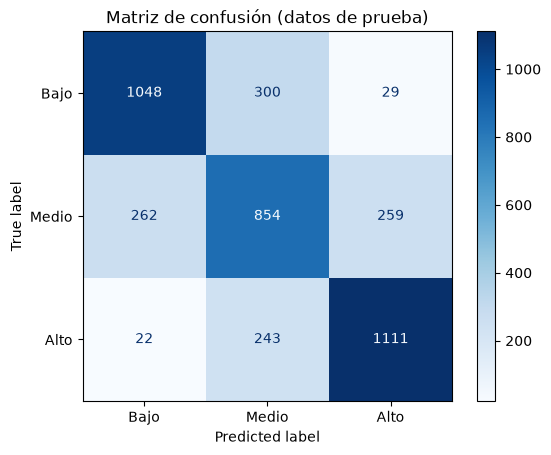

In [17]:
cm = confusion_matrix(y_test_clf, pred_clf, labels=clases)
display(pd.DataFrame(cm,
                     index=[f"Real: {c}" for c in clases],
                     columns=[f"Predicho: {c}" for c in clases]))

ConfusionMatrixDisplay(cm, display_labels=clases).plot(cmap="Blues")
plt.title("Matriz de confusión (datos de prueba)")
plt.show()

### Coeficientes

In [18]:
coef_clf = pd.DataFrame(modelo_clf.coef_.T, index=predictoras, columns=modelo_clf.classes_).round(3)
display(coef_clf)
print("Orden de las clases en el modelo:", list(modelo_clf.classes_))
print("Interceptos:", modelo_clf.intercept_.round(3))

,Alto,Bajo,Medio
Ingreso_mediano,2.209,-2.447,0.238
Edad_vivienda,0.325,-0.201,-0.123
Promedio_habitaciones,-1.678,1.550,0.128
Promedio_dormitorio_hogar,1.286,-1.168,-0.118
Poblacion,0.177,-0.141,-0.037
Promedio_ocupacion,-0.751,0.499,0.252
Latitud,-3.123,2.917,0.206
Longitud,-2.914,2.689,0.225
Habitaciones_por_dormitorio,1.238,-0.937,-0.300


Orden de las clases en el modelo: ['Alto', 'Bajo', 'Medio']
Interceptos: [-0.336 -0.433  0.769]


### Resultados en datos de prueba

El conjunto de prueba tiene 4.128 zonas, con las clases casi perfectamente balanceadas (1.377 Bajo, 1.375 Medio y 1.376 Alto).

| Métrica | Valor |
|---|---|
| Exactitud (accuracy) | 0.730 |
| F1 macro | 0.730 |
| Exactitud del modelo base (siempre la clase más frecuente) | 0.334 |

El modelo base acierta cerca de un tercio de las veces, lo esperable con tres clases balanceadas. El modelo logístico lo supera por casi 40 puntos porcentuales, así que aprende información útil de las variables.

**Métricas por clase**

| Clase | Precisión | Recall | F1 |
|---|---|---|---|
| Bajo | 0.787 | 0.761 | 0.774 |
| Medio | 0.611 | 0.621 | 0.616 |
| Alto | 0.794 | 0.807 | 0.801 |

**Matriz de confusión (filas: clase real, columnas: clase predicha)**

| | Predicho: Bajo | Predicho: Medio | Predicho: Alto |
|---|---|---|---|
| **Real: Bajo** | 1048 | 300 | 29 |
| **Real: Medio** | 262 | 854 | 259 |
| **Real: Alto** | 22 | 243 | 1111 |

**Por qué estas métricas:** como las clases están balanceadas, la exactitud es una medida válida y no engañosa. El F1 macro confirma que el rendimiento no depende de una sola clase, y la precisión y el recall por clase muestran dónde está el error.

### Interpretacion de los resultados

- **Clases que mejor reconoce:** `Alto` (F1 0.801, recall 0.807) y `Bajo` (F1 0.774, recall 0.761). Las zonas caras y las baratas tienen características más marcadas, y el modelo las separa con más facilidad.
- **Clase más difícil:** `Medio` (F1 0.616). Es la que más se confunde: 521 de sus 1.375 zonas (cerca del 38 %) se clasifican mal, frente a un 24 % en `Bajo` y un 19 % en `Alto`.
- **Tipo de errores:** de los 1.115 errores, 1.064 (cerca del 95 %) ocurren entre **clases vecinas** (Bajo con Medio, y Medio con Alto). Los errores extremos, como predecir `Alto` para una zona `Bajo` o al revés, son solo 51 (alrededor del 1 % de las zonas de prueba). Esto es coherente con que las clases tienen un orden: cuando el modelo se equivoca, lo hace por poco.
- **Por qué `Medio` es la más difícil:** las fronteras entre clases son cortes arbitrarios (terciles) de una variable continua. Una zona justo por encima o por debajo de un corte es casi idéntica a una de la clase vecina, y `Medio` tiene fronteras con las dos clases.

### Interpretacion de los coeficientes

Las predictoras están estandarizadas y cuatro de ellas (`Promedio_habitaciones`, `Promedio_dormitorio_hogar`, `Promedio_ocupacion` y `Poblacion`) están en escala logarítmica. El modelo calcula un puntaje por clase, y un coeficiente positivo aumenta la probabilidad de esa clase frente a las otras cuando la variable sube una desviación estándar. En la tabla, las columnas salen en orden alfabético (`Alto`, `Bajo`, `Medio`).

- **`Latitud` (Alto -3.123, Bajo +2.917) y `Longitud` (Alto -2.914, Bajo +2.689):** son los coeficientes más grandes. Hacia el norte y hacia el este (hacia el interior), aumenta la probabilidad de `Bajo` y disminuye la de `Alto`. Coincide con la regresión lineal, donde estas dos variables también tenían los mayores coeficientes negativos.
- **`Ingreso_mediano` (Alto +2.209, Bajo -2.447):** un mayor ingreso aumenta mucho la probabilidad de `Alto` y reduce la de `Bajo`. Es la variable más directa de interpretar.
- **`Promedio_habitaciones` (Alto -1.678, Bajo +1.550) y `Promedio_dormitorio_hogar` (Alto +1.286, Bajo -1.168):** tienen signos opuestos y no deben interpretarse por separado, porque están correlacionadas (0.518) y el modelo las usa en conjunto, igual que en la regresión. `Habitaciones_por_dormitorio` (Alto +1.238, Bajo -0.937) refuerza la asociación de más habitaciones por dormitorio con zonas de mayor valor.
- **`Promedio_ocupacion` (Alto -0.751, Bajo +0.499):** más personas por hogar se asocia con zonas más baratas.
- **`Edad_vivienda` (Alto +0.325, Bajo -0.201) y `Poblacion` (Alto +0.177, Bajo -0.141):** tienen un efecto pequeño.
- **Clase `Medio`:** todos sus coeficientes son pequeños (entre -0.300 y +0.252). Ninguna variable la caracteriza por sí sola, porque `Medio` es la clase intermedia: se predice cuando una zona no es claramente `Bajo` ni `Alto`. Esto explica su menor F1.
- **Interceptos (Alto -0.336, Bajo -0.433, Medio +0.769):** corresponden a una zona con todas las predictoras en su promedio. El mayor valor lo tiene `Medio`, es decir, una zona promedio se inclina hacia la clase intermedia, algo coherente con que las clases son terciles.

Los coeficientes describen **asociaciones**, no causas.

### Limitaciones

- **Fronteras arbitrarias:** los terciles dividen una variable continua, por lo que zonas casi idénticas quedan en clases distintas y parte del error es inevitable.
- **Modelo lineal:** la relación entre la ubicación y la clase no es lineal (hay zonas caras en el interior y baratas en la costa), por lo que el modelo capta la tendencia general de costa a interior, pero no los patrones locales. Un modelo no lineal, como un bosque aleatorio, podría rendir mejor.
- **Variables correlacionadas:** `Latitud` y `Longitud`, y las variables de habitaciones y dormitorios, están relacionadas entre sí, lo que hace inestables sus coeficientes individuales.
- **Tope en el objetivo:** muchas zonas caras comparten el valor máximo, lo que influye en la clase `Alto`.
- **Una sola división:** los resultados salen de una única partición de entrenamiento y prueba (`random_state=42`); no se usó validación cruzada, por lo que no se midió cuánto varían al cambiar la partición.
- **Etiquetas definidas con todo el dataset:** los terciles se calcularon antes de dividir. Es aceptable porque definen la etiqueta, pero es una limitación.
- **Datos agregados y antiguos:** cada fila es una zona del censo de 1990, no una vivienda individual.

## **4. Resumen automático de los dos modelos en un archivo .txt**

In [19]:
# ---------- Resumen automático de ambos modelos en un .txt ----------
# Carpeta de salida: reportes/ en la raíz del proyecto (donde está requirements.txt)
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists()), Path.cwd())
ruta_txt = raiz / "src" / "notebook" / "reportes" / "entrega_2" / "resumen_modelos.txt"

# --- Valores calculados en esta ejecución ---
cols_log = ["Promedio_ocupacion", "Promedio_dormitorio_hogar", "Promedio_habitaciones", "Poblacion"]
rangos = df_modelo.groupby("Categoria_valor", observed=False)["Valor_mediano_vivienda"].agg(["min", "max"])

coef_reg = pd.Series(modelo_reg.coef_, index=predictoras)
mejora_mae = (1 - mae / mae_base) * 100

rep = classification_report(y_test_clf, pred_clf, labels=clases, output_dict=True, zero_division=0)
acc = accuracy_score(y_test_clf, pred_clf)
f1_macro = f1_score(y_test_clf, pred_clf, average="macro")
mejor = max(clases, key=lambda c: rep[c]["f1-score"])
peor = min(clases, key=lambda c: rep[c]["f1-score"])
errores = int(cm.sum() - np.trace(cm))
extremos = int(cm[0, 2] + cm[2, 0])          # Bajo<->Alto
vecinos = errores - extremos                 # Bajo<->Medio y Medio<->Alto
coef_alto = pd.Series(modelo_clf.coef_[list(modelo_clf.classes_).index("Alto")], index=predictoras)

# --- Construcción del texto ---
L = []
def seccion(titulo):
    L.extend(["", "=" * 70, titulo, "=" * 70])

L += [
    "RESUMEN AUTOMÁTICO DE LOS MODELOS",
    f"Fecha de ejecución: {datetime.now():%Y-%m-%d %H:%M:%S}",
    f"Python {platform.python_version()} | pandas {pd.__version__} | "
    f"numpy {np.__version__} | scikit-learn {sklearn.__version__}",
]

seccion("1. DATASET Y PREPROCESAMIENTO")
L += [
    f"Dataset: {DATASET} (split '{SPLIT}')",
    f"Tamaño original: {df.shape[0]} filas x {df.shape[1]} columnas",
    f"Nulos: {int(df_modelo.isna().sum().sum())} | Duplicados: {int(df_modelo.duplicated().sum())}",
    "",
    "Preprocesamiento aplicado:",
    "- Renombrado de columnas al español.",
    "- Variable de clasificación 'Categoria_valor' con terciles de Valor_mediano_vivienda:",
    *[f"    {c}: de {rangos.loc[c, 'min']:.3f} a {rangos.loc[c, 'max']:.3f}" for c in clases],
    "- Enriquecimiento: Habitaciones_por_dormitorio = Promedio_habitaciones / Promedio_dormitorio_hogar",
    f"- Transformación log1p en: {', '.join(cols_log)}",
    "  Asimetría antes -> después:",
    *[f"    {c}: {asimetria_antes[c]} -> {asimetria_despues[c]}" for c in cols_log],
    f"- División: {len(train_df)} filas de entrenamiento y {len(test_df)} de prueba "
    f"({len(test_df) / len(df_prep):.0%} prueba), estratificada por Categoria_valor, random_state=42",
    "- Escalado con StandardScaler ajustado solo con entrenamiento y aplicado a prueba.",
    f"- Predictoras ({len(predictoras)}): {', '.join(predictoras)}",
]

seccion("2. MODELO DE REGRESIÓN LINEAL")
L += [
    "Objetivo: Valor_mediano_vivienda (cientos de miles de USD)",
    f"Predictoras: {', '.join(predictoras)}",
    f"Algoritmo: {type(modelo_reg).__name__}",
    f"Parámetros: {modelo_reg.get_params()}",
    f"Entrenamiento: {len(X_train_esc)} filas | Prueba: {len(X_test_esc)} filas",
    "",
    "Métricas en prueba:",
    f"  MAE:  {mae:.3f} (aprox. {mae * 100000:,.0f} USD)",
    f"  RMSE: {rmse:.3f} (aprox. {rmse * 100000:,.0f} USD)",
    f"  R2:   {r2:.3f}",
    f"  MAE del modelo base (promedio): {mae_base:.3f}",
    f"Intercepto: {modelo_reg.intercept_:.4f}",
    "Coeficientes estandarizados:",
    *[f"  {v}: {coef_reg[v]:+.4f}" for v in coef_reg.abs().sort_values(ascending=False).index],
    "",
    "Interpretación:",
    f"- El modelo explica {r2:.1%} de la variación del valor de las viviendas.",
    f"- Se equivoca en promedio {mae * 100000:,.0f} USD, un {mejora_mae:.0f}% menos que el modelo base.",
    f"- Mayor efecto: {coef_reg.abs().idxmax()} ({coef_reg[coef_reg.abs().idxmax()]:+.4f}).",
]

seccion("3. MODELO DE CLASIFICACIÓN (REGRESIÓN LOGÍSTICA)")
L += [
    f"Objetivo: Categoria_valor (clases: {', '.join(clases)})",
    f"Predictoras: {', '.join(predictoras)}",
    f"Algoritmo: {type(modelo_clf).__name__}",
    f"Parámetros: {modelo_clf.get_params()}",
    f"Entrenamiento: {len(X_train_esc)} filas | Prueba: {len(X_test_esc)} filas",
    "",
    "Métricas en prueba:",
    f"  Exactitud: {acc:.3f}",
    f"  F1 macro:  {f1_macro:.3f}",
    f"  Exactitud del modelo base (clase más frecuente): {acc_base:.3f}",
    "",
    classification_report(y_test_clf, pred_clf, labels=clases, digits=3),
    "Matriz de confusión (filas: real, columnas: predicho):",
    pd.DataFrame(cm, index=[f"Real {c}" for c in clases],
                 columns=[f"Pred {c}" for c in clases]).to_string(),
    "",
    "Interpretación:",
    f"- Clase mejor reconocida: {mejor} (F1 {rep[mejor]['f1-score']:.3f}); más difícil: {peor} (F1 {rep[peor]['f1-score']:.3f}).",
    f"- Errores totales: {errores}; entre clases vecinas: {vecinos} ({vecinos / errores:.0%}); extremos (Bajo<->Alto): {extremos}.",
    f"- Variable con mayor peso para 'Alto': {coef_alto.abs().idxmax()} ({coef_alto[coef_alto.abs().idxmax()]:+.3f}).",
]

seccion("4. CONCLUSIONES Y LIMITACIONES")
L += [
    f"- La regresión {'supera' if mae < mae_base else 'no supera'} a su referencia (MAE {mae:.3f} vs {mae_base:.3f}) "
    f"y la clasificación {'supera' if acc > acc_base else 'no supera'} a la suya (exactitud {acc:.3f} vs {acc_base:.3f}).",
    f"- La regresión deja {1 - r2:.1%} de la variación sin explicar.",
    "- Son modelos lineales: la ubicación (Latitud/Longitud) tiene una relación no lineal con el precio.",
    "- Los terciles de Categoria_valor se calcularon con todo el dataset antes de dividir.",
    "- Resultados de una sola partición entrenamiento/prueba, sin validación cruzada.",
    f"- Asimetría residual tras el logaritmo: "
    f"{', '.join(f'{c} ({asimetria_despues[c]})' for c in cols_log)}.",
]

# --- Guardar y mostrar ---
ruta_txt.parent.mkdir(parents=True, exist_ok=True)
ruta_txt.write_text("\n".join(L) + "\n", encoding="utf-8")
print("Resumen guardado en:", ruta_txt, "\n")
print(ruta_txt.read_text(encoding="utf-8"))

Resumen guardado en: /workspaces/Machine-Learning/src/notebook/reportes/entrega_2/resumen_modelos.txt 

RESUMEN AUTOMÁTICO DE LOS MODELOS
Fecha de ejecución: 2026-10-23 02:17:32
Python 3.14.2 | pandas 2.2.3 | numpy 2.5.4 | scikit-learn 1.9.1

1. DATASET Y PREPROCESAMIENTO
Dataset: BrianSuToronto/california_housing (split 'train')
Tamaño original: 20640 filas x 9 columnas
Nulos: 0 | Duplicados: 0

Preprocesamiento aplicado:
- Renombrado de columnas al español.
- Variable de clasificación 'Categoria_valor' con terciles de Valor_mediano_vivienda:
    Bajo: de 0.150 a 1.414
    Medio: de 1.415 a 2.303
    Alto: de 2.304 a 5.000
- Enriquecimiento: Habitaciones_por_dormitorio = Promedio_habitaciones / Promedio_dormitorio_hogar
- Transformación log1p en: Promedio_ocupacion, Promedio_dormitorio_hogar, Promedio_habitaciones, Poblacion
  Asimetría antes -> después:
    Promedio_ocupacion: 97.64 -> 3.88
    Promedio_dormitorio_hogar: 31.32 -> 8.99
    Promedio_habitaciones: 20.7 -> 1.39
    Pobla